# Import Required Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# PCA
from sklearn.decomposition import PCA

# Train/Test Split and Hyperparameter Tuning
from sklearn.model_selection import train_test_split, GridSearchCV

# Regression Models
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Evaluation Metrics
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Statistical Analysis
from scipy.stats import pearsonr, f_oneway

# Display settings
pd.set_option('display.max_columns', None)

# Reproducibility
RANDOM_STATE = 42

# Plot settings
sns.set_theme(style="whitegrid")

# Load Dataset

In [3]:
df = pd.read_csv('Crop_Data.csv')

# Preserve the original dataset
df_raw = df.copy()

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (2000, 14)


# Data Understanding and Exploration

In [4]:
df.head()

,Crop_Type,Region,Soil_Type,Rainfall_mm,Temperature_C,Humidity_percent,pH_Level,Nitrogen_kg_per_hectare,Phosphorus_kg_per_hectare,Potassium_kg_per_hectare,Irrigation_Days,Fertilizer_Used,Pesticide_Used,Yield_tons_per_hectare
0,Soybean,Central,Loamy,929.5,32.6,61.5,6.27,73.7,37.7,34.4,70,1,1,1.56
1,Barley,West,Clay,963.3,17.4,58.6,5.76,39.4,8.6,32.4,104,1,1,0.99
2,Barley,East,Loamy,679.9,29.7,69.4,5.86,34.7,28.4,33.6,130,0,1,1.34
3,Rice,South,Silty,843.7,29.4,49.9,4.92,61.6,24.6,23.8,173,0,0,2.23
4,Barley,North,Clay,916.4,29.4,78.4,7.25,46.9,23.8,21.9,97,1,1,1.25


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 2000
Number of columns: 14

Column names:
['Crop_Type', 'Region', 'Soil_Type', 'Rainfall_mm', 'Temperature_C', 'Humidity_percent', 'pH_Level', 'Nitrogen_kg_per_hectare', 'Phosphorus_kg_per_hectare', 'Potassium_kg_per_hectare', 'Irrigation_Days', 'Fertilizer_Used', 'Pesticide_Used', 'Yield_tons_per_hectare']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Crop_Type                  2000 non-null   object 
 1   Region                     2000 non-null   object 
 2   Soil_Type                  2000 non-null   object 
 3   Rainfall_mm                2000 non-null   float64
 4   Temperature_C              2000 non-null   float64
 5   Humidity_percent           2000 non-null   float64
 6   pH_Level                   2000 non-null   float64
 7   Nitrogen_kg_per_hectare    2000 non-null   float64
 8   Phosphorus_kg_per_hectare  2000 non-null   float64
 9   Potassium_kg_per_hectare   2000 non-null   float64
 10  Irrigation_Days            2000 non-null   int64  
 11  Fertilizer_Used            2000 non-null   int64  
 12  Pesticide_Used             2000 non-null   int64  
 13  Yield_tons_per_hectare     2000 non-null   float

In [82]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,2000.0,808.227950,204.918392,200.0,669.25,810.65,946.825,1500.00
Temperature_C,2000.0,24.976200,5.008742,10.4,21.60,25.10,28.400,40.00
Humidity_percent,2000.0,65.604850,13.865347,30.0,55.50,65.65,75.700,90.00
pH_Level,2000.0,6.497760,1.001026,4.0,5.84,6.46,7.170,9.00
Nitrogen_kg_per_hectare,2000.0,49.582350,14.783001,10.0,39.20,49.60,59.300,99.10
Phosphorus_kg_per_hectare,2000.0,30.210450,9.886475,5.0,23.80,30.30,36.925,60.00
Potassium_kg_per_hectare,2000.0,40.015400,12.202466,10.0,31.70,39.80,48.500,80.00
Irrigation_Days,2000.0,115.660500,38.211992,50.0,81.00,117.00,150.000,179.00
Fertilizer_Used,2000.0,0.706500,0.455479,0.0,0.00,1.00,1.000,1.00
Pesticide_Used,2000.0,0.611000,0.487645,0.0,0.00,1.00,1.000,1.00


## Unique Categorical Values

In [11]:
print("Crop Types:")
print(df['Crop_Type'].unique())

print("\nRegions:")
print(df['Region'].unique())

print("\nSoil Types:")
print(df['Soil_Type'].unique())

Crop Types:
['Soybean' 'Barley' 'Rice' 'Wheat' 'Corn']

Regions:
['Central' 'West' 'East' 'South' 'North']

Soil Types:
['Loamy' 'Clay' 'Silty' 'Sandy']


In [12]:
unique_summary = pd.DataFrame({
    'Feature': ['Crop_Type', 'Region', 'Soil_Type'],
    'Unique_Count': [
        df['Crop_Type'].nunique(),
        df['Region'].nunique(),
        df['Soil_Type'].nunique()
    ]
})

unique_summary

,Feature,Unique_Count
0,Crop_Type,5
1,Region,5
2,Soil_Type,4


# Data Cleaning and Quality Checks

In [13]:
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values by column:
Crop_Type                    0
Region                       0
Soil_Type                    0
Rainfall_mm                  0
Temperature_C                0
Humidity_percent             0
pH_Level                     0
Nitrogen_kg_per_hectare      0
Phosphorus_kg_per_hectare    0
Potassium_kg_per_hectare     0
Irrigation_Days              0
Fertilizer_Used              0
Pesticide_Used               0
Yield_tons_per_hectare       0
dtype: int64

Total missing values: 0


In [15]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


# Exploratory Data Analysis (EDA)

## Target Distribution

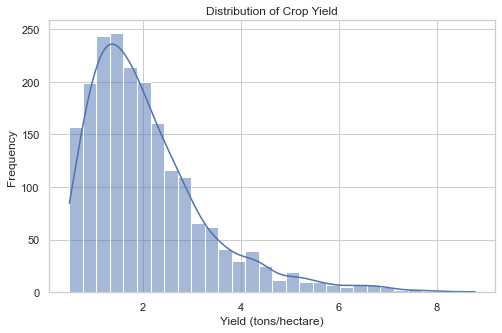

In [84]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['Yield_tons_per_hectare'],
    bins=30,
    kde=True
)

plt.title('Distribution of Crop Yield')
plt.xlabel('Yield (tons/hectare)')
plt.ylabel('Frequency')

plt.show()

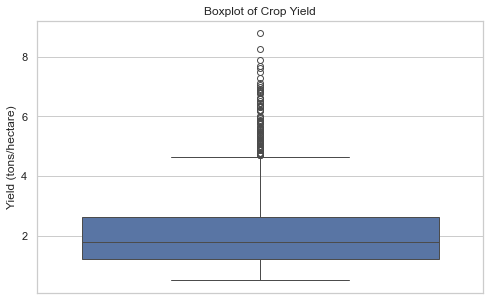

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    y=df['Yield_tons_per_hectare']
)

plt.title('Boxplot of Crop Yield')
plt.ylabel('Yield (tons/hectare)')

plt.show()

## Crop distribution

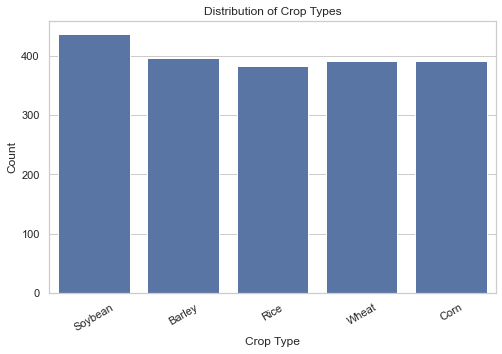

In [93]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Crop_Type'
)

plt.title('Distribution of Crop Types')
plt.xlabel('Crop Type')
plt.ylabel('Count')

plt.xticks(rotation=30)

plt.show()

## Region distribution

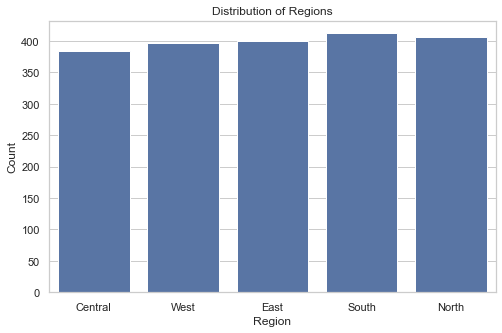

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Region'
)

plt.title('Distribution of Regions')
plt.xlabel('Region')
plt.ylabel('Count')

plt.show()

## Soil distribution

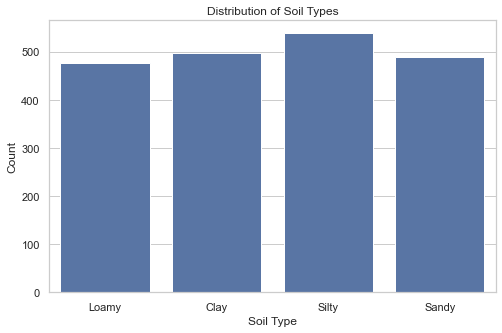

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Soil_Type'
)

plt.title('Distribution of Soil Types')
plt.xlabel('Soil Type')
plt.ylabel('Count')

plt.show()

## Yield by crop

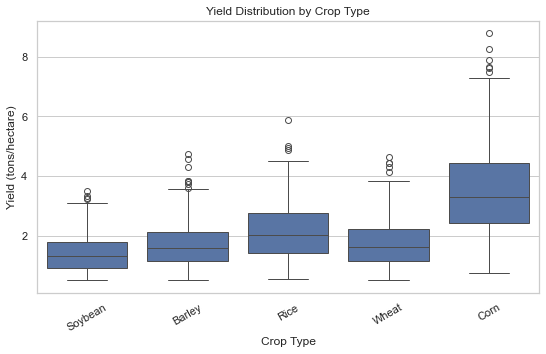

In [102]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Crop_Type',
    y='Yield_tons_per_hectare'
)

plt.title('Yield Distribution by Crop Type')
plt.xlabel('Crop Type')
plt.ylabel('Yield (tons/hectare)')

plt.xticks(rotation=30)

plt.show()

## Yield by region

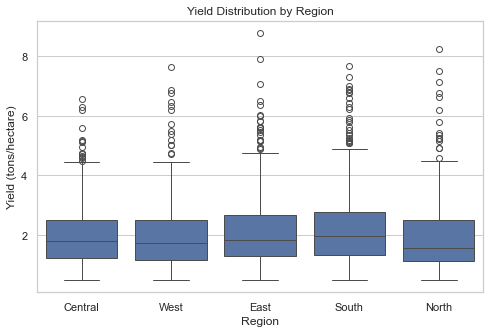

In [103]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Region',
    y='Yield_tons_per_hectare'
)

plt.title('Yield Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Yield (tons/hectare)')

plt.show()

## Yield by soil

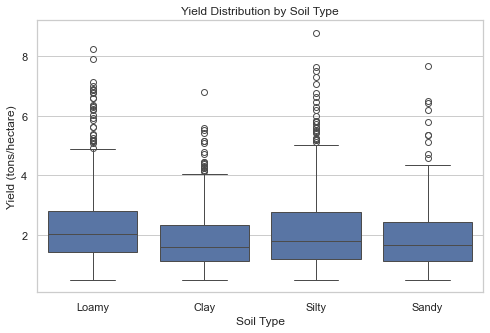

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Soil_Type',
    y='Yield_tons_per_hectare'
)

plt.title('Yield Distribution by Soil Type')
plt.xlabel('Soil Type')
plt.ylabel('Yield (tons/hectare)')

plt.show()

# CORRELATION ANALYSIS

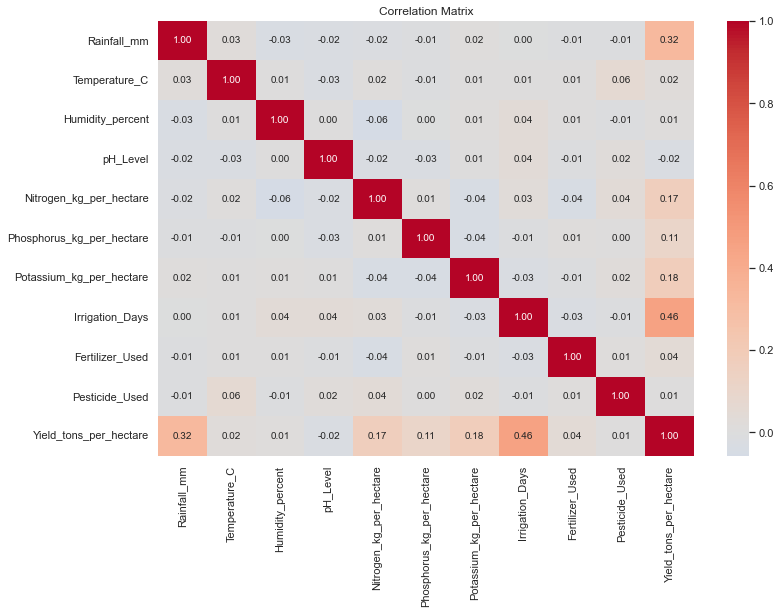

In [105]:
numeric_columns = [
    'Rainfall_mm',
    'Temperature_C',
    'Humidity_percent',
    'pH_Level',
    'Nitrogen_kg_per_hectare',
    'Phosphorus_kg_per_hectare',
    'Potassium_kg_per_hectare',
    'Irrigation_Days',
    'Fertilizer_Used',
    'Pesticide_Used',
    'Yield_tons_per_hectare'
]

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix')

plt.show()

# STATISTICAL ANALYSIS

A significance level of α = 0.05 is used.

The statistical analysis evaluates whether observed relationships between numerical variables and yield are statistically significant.

### Hypotheses for correlation

H0: There is no statistically significant linear relationship between the selected feature and crop yield.

H1: There is a statistically significant linear relationship between the selected feature and crop yield.

In [121]:
correlation_results = []

features_for_test = [
    'Rainfall_mm',
    'Temperature_C',
    'Humidity_percent',
    'pH_Level',
    'Nitrogen_kg_per_hectare',
    'Phosphorus_kg_per_hectare',
    'Potassium_kg_per_hectare',
    'Irrigation_Days'
]

for feature in features_for_test:

    correlation, p_value = pearsonr(
        df[feature],
        df['Yield_tons_per_hectare']
    )

    correlation_results.append({
        'Feature': feature,
        'Pearson_Correlation': correlation,
        'P_Value': p_value,
        'Significant_at_0.05': 'Yes' if p_value < 0.05 else 'No'
    })

correlation_results_df = pd.DataFrame(
    correlation_results
)

correlation_results_df.sort_values(
    by='Pearson_Correlation',
    key=abs,
    ascending=False
).round(4)

,Feature,Pearson_Correlation,P_Value,Significant_at_0.05
7,Irrigation_Days,0.4558,0.0000,Yes
0,Rainfall_mm,0.3198,0.0000,Yes
6,Potassium_kg_per_hectare,0.1812,0.0000,Yes
4,Nitrogen_kg_per_hectare,0.1734,0.0000,Yes
5,Phosphorus_kg_per_hectare,0.1104,0.0000,Yes
1,Temperature_C,0.0207,0.3546,No
3,pH_Level,-0.0204,0.3626,No
2,Humidity_percent,0.0103,0.6441,No


# OUTLIER CHECK

In [122]:
# Outlier detection using the IQR method

outlier_results = []

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_results.append({
        'Feature': column,
        'Q1': Q1,
        'Q3': Q3,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': outlier_count
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Q1,Q3,Lower_Bound,Upper_Bound,Outlier_Count
0,Rainfall_mm,669.25,946.825,252.8875,1363.1875,15
1,Temperature_C,21.60,28.400,11.4000,38.6000,14
2,Humidity_percent,55.50,75.700,25.2000,106.0000,0
3,pH_Level,5.84,7.170,3.8450,9.1650,0
4,Nitrogen_kg_per_hectare,39.20,59.300,9.0500,89.4500,8
5,Phosphorus_kg_per_hectare,23.80,36.925,4.1125,56.6125,8
6,Potassium_kg_per_hectare,31.70,48.500,6.5000,73.7000,6
7,Irrigation_Days,81.00,150.000,-22.5000,253.5000,0
8,Fertilizer_Used,0.00,1.000,-1.5000,2.5000,0
9,Pesticide_Used,0.00,1.000,-1.5000,2.5000,0


## Outlier Treatment

The IQR method identified potential outliers in several numerical variables, including crop yield.

These observations were not automatically removed because statistical outliers are not necessarily data errors. The logical range validation showed that the observations fall within the expected domain ranges of the variables.

Therefore, the observations were retained for further analysis and modeling to avoid losing potentially meaningful agricultural information.

The outlier analysis is treated as a diagnostic step rather than an automatic data-removal step.

# FEATURE ENGINEERING

In [32]:
# Create label encoders
le_crop = LabelEncoder()
le_region = LabelEncoder()
le_soil = LabelEncoder()

# Encode categorical variables
df['Crop_Type_encoded'] = le_crop.fit_transform(
    df['Crop_Type']
)

df['Region_encoded'] = le_region.fit_transform(
    df['Region']
)

df['Soil_Type_encoded'] = le_soil.fit_transform(
    df['Soil_Type']
)

In [33]:
print("Crop Type Encoding:")
print(
    dict(
        zip(
            le_crop.classes_,
            le_crop.transform(le_crop.classes_)
        )
    )
)

print("\nRegion Encoding:")
print(
    dict(
        zip(
            le_region.classes_,
            le_region.transform(le_region.classes_)
        )
    )
)

print("\nSoil Type Encoding:")
print(
    dict(
        zip(
            le_soil.classes_,
            le_soil.transform(le_soil.classes_)
        )
    )
)

Crop Type Encoding:
{'Barley': 0, 'Corn': 1, 'Rice': 2, 'Soybean': 3, 'Wheat': 4}

Region Encoding:
{'Central': 0, 'East': 1, 'North': 2, 'South': 3, 'West': 4}

Soil Type Encoding:
{'Clay': 0, 'Loamy': 1, 'Sandy': 2, 'Silty': 3}


# FEATURES AND TARGET

In [34]:
feature_columns = [
    'Rainfall_mm',
    'Temperature_C',
    'Humidity_percent',
    'pH_Level',
    'Nitrogen_kg_per_hectare',
    'Phosphorus_kg_per_hectare',
    'Potassium_kg_per_hectare',
    'Irrigation_Days',
    'Fertilizer_Used',
    'Pesticide_Used',
    'Crop_Type_encoded',
    'Region_encoded',
    'Soil_Type_encoded'
]

X = df[feature_columns].copy()

y = df['Yield_tons_per_hectare'].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (2000, 13)
Target shape: (2000,)


# FEATURE SCALING

In [35]:
scaler_cluster = StandardScaler()

X_cluster_scaled = scaler_cluster.fit_transform(X)

print("Scaled feature matrix shape:", X_cluster_scaled.shape)

Scaled feature matrix shape: (2000, 13)


# Optimal Number of Clusters

In [36]:
wcss = []

k_values = range(1, 11)

for k in k_values:

    kmeans_model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    kmeans_model.fit(X_cluster_scaled)

    wcss.append(
        kmeans_model.inertia_
    )

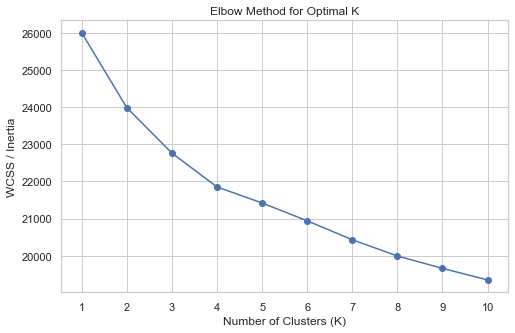

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    wcss,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.title('Elbow Method for Optimal K')

plt.xticks(k_values)

plt.show()

## SILHOUETTE ANALYSIS

In [124]:
silhouette_results = []

for k in range(2, 11):

    kmeans_model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = kmeans_model.fit_predict(
        X_cluster_scaled
    )

    score = silhouette_score(
        X_cluster_scaled,
        labels
    )

    silhouette_results.append({
        'K': k,
        'Silhouette_Score': score
    })

silhouette_df = pd.DataFrame(
    silhouette_results
)

silhouette_df

,K,Silhouette_Score
0,2,0.084837
1,3,0.077572
2,4,0.060195
3,5,0.058833
4,6,0.053142
5,7,0.060886
6,8,0.062018
7,9,0.061861
8,10,0.058714


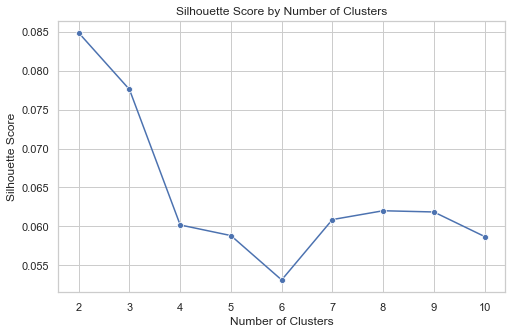

In [39]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=silhouette_df,
    x='K',
    y='Silhouette_Score',
    marker='o'
)

plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.show()

## Cluster Selection

Based on the elbow analysis and the clustering structure observed in the dataset, K=4 is selected for the final K-Means analysis.

The silhouette analysis is included as an additional validation measure for the selected clustering solution.


# K-Means Clustering

In [40]:
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=RANDOM_STATE,
    n_init=10
)

clusters = kmeans.fit_predict(
    X_cluster_scaled
)

df['Cluster'] = clusters

print("Cluster assignment completed.")
print("\nCluster counts:")
print(df['Cluster'].value_counts().sort_index())

Cluster assignment completed.

Cluster counts:
Cluster
0    545
1    587
2    395
3    473
Name: count, dtype: int64


# CLUSTER PROFILING

Each cluster is analyzed using yield statistics, crop composition, regional composition, soil composition, and numerical feature averages.

This helps explain the characteristics of different crop-growing condition groups.

In [41]:
cluster_yield = df.groupby(
    'Cluster'
)['Yield_tons_per_hectare'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(3)

cluster_yield

,count,mean,median,std,min,max
Cluster,,,,,,
0,545,2.123,1.85,1.258,0.50,7.67
1,587,2.000,1.68,1.263,0.50,8.24
2,395,2.558,2.23,1.413,0.58,8.78
3,473,1.746,1.61,0.822,0.50,5.36


In [125]:
cluster_numeric_profile = df.groupby(
    'Cluster'
)[
    [
        'Rainfall_mm',
        'Temperature_C',
        'Humidity_percent',
        'pH_Level',
        'Nitrogen_kg_per_hectare',
        'Phosphorus_kg_per_hectare',
        'Potassium_kg_per_hectare',
        'Irrigation_Days',
        'Fertilizer_Used',
        'Pesticide_Used',
        'Yield_tons_per_hectare'
    ]
].mean().round(3).T

cluster_numeric_profile

Cluster,0,1,2,3
Rainfall_mm,808.117,811.329,829.080,787.095
Temperature_C,24.859,24.925,25.003,25.153
Humidity_percent,66.006,65.411,64.061,66.673
pH_Level,6.498,6.509,6.284,6.662
Nitrogen_kg_per_hectare,48.890,50.440,51.530,47.690
Phosphorus_kg_per_hectare,30.521,30.051,28.523,31.459
Potassium_kg_per_hectare,39.485,40.165,39.408,40.948
Irrigation_Days,115.431,117.153,117.866,112.230
Fertilizer_Used,1.000,0.000,1.000,1.000
Pesticide_Used,0.000,0.603,1.000,1.000


In [127]:
cluster_crop = pd.crosstab(
    df['Cluster'],
    df['Crop_Type']
)

cluster_crop

Crop_Type,Barley,Corn,Rice,Soybean,Wheat
Cluster,,,,,
0,116,129,110,109,81
1,114,111,102,129,131
2,167,145,78,5,0
3,0,7,93,194,179


In [44]:
cluster_region = pd.crosstab(
    df['Cluster'],
    df['Region']
)

cluster_region

Region,Central,East,North,South,West
Cluster,,,,,
0,119,108,98,97,123
1,107,121,125,118,116
2,46,77,82,103,87
3,112,94,102,94,71


In [45]:
cluster_soil = pd.crosstab(
    df['Cluster'],
    df['Soil_Type']
)

cluster_soil

Soil_Type,Clay,Loamy,Sandy,Silty
Cluster,,,,
0,142,125,128,150
1,132,149,138,168
2,89,84,111,111
3,134,119,111,109


# DOMINANT CHARACTERISTICS

In [46]:
dominant_cluster_characteristics = []

for cluster in sorted(df['Cluster'].unique()):

    cluster_data = df[df['Cluster'] == cluster]

    dominant_crop = cluster_data['Crop_Type'].mode()[0]
    dominant_region = cluster_data['Region'].mode()[0]
    dominant_soil = cluster_data['Soil_Type'].mode()[0]

    dominant_cluster_characteristics.append({
        'Cluster': cluster,
        'Mean_Yield': cluster_data['Yield_tons_per_hectare'].mean(),
        'Dominant_Crop': dominant_crop,
        'Dominant_Region': dominant_region,
        'Dominant_Soil': dominant_soil
    })

dominant_characteristics_df = pd.DataFrame(
    dominant_cluster_characteristics
).round(3)

dominant_characteristics_df

,Cluster,Mean_Yield,Dominant_Crop,Dominant_Region,Dominant_Soil
0,0,2.123,Corn,West,Silty
1,1,2.000,Wheat,North,Silty
2,2,2.558,Barley,South,Sandy
3,3,1.746,Soybean,Central,Clay


# TOP-PERFORMING CLUSTER

In [47]:
top_cluster = cluster_yield['mean'].idxmax()

top_cluster_yield = cluster_yield.loc[
    top_cluster,
    'mean'
]

lowest_cluster = cluster_yield['mean'].idxmin()

lowest_cluster_yield = cluster_yield.loc[
    lowest_cluster,
    'mean'
]

print("Top-performing cluster:", top_cluster)
print(
    "Top cluster average yield:",
    round(top_cluster_yield, 3),
    "tons/hectare"
)

print("\nLowest-performing cluster:", lowest_cluster)
print(
    "Lowest cluster average yield:",
    round(lowest_cluster_yield, 3),
    "tons/hectare"
)

Top-performing cluster: 2
Top cluster average yield: 2.558 tons/hectare

Lowest-performing cluster: 3
Lowest cluster average yield: 1.746 tons/hectare


# PCA

In [48]:
pca = PCA(n_components=2)

principal_components = pca.fit_transform(
    X_cluster_scaled
)

pca_df = pd.DataFrame(
    principal_components,
    columns=['PC1', 'PC2']
)

pca_df['Cluster'] = clusters

In [49]:
print(
    "PC1 explained variance:",
    round(
        pca.explained_variance_ratio_[0] * 100,
        2
    ),
    "%"
)

print(
    "PC2 explained variance:",
    round(
        pca.explained_variance_ratio_[1] * 100,
        2
    ),
    "%"
)

print(
    "Total variance explained:",
    round(
        pca.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

PC1 explained variance: 8.73 %
PC2 explained variance: 8.35 %
Total variance explained: 17.09 %


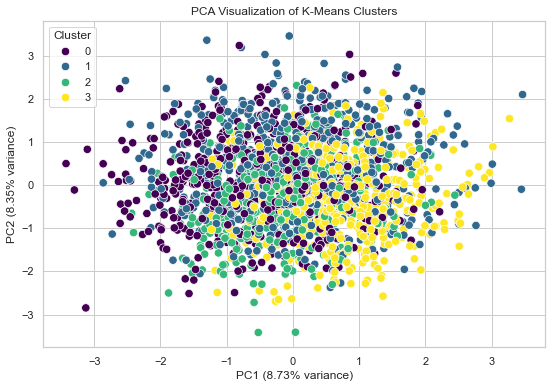

In [50]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='viridis',
    s=70
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)"
)

plt.title('PCA Visualization of K-Means Clusters')

plt.legend(title='Cluster')

plt.show()

# TRAIN/TEST SPLIT

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (1600, 13)
Testing feature shape: (400, 13)
Training target shape: (1600,)
Testing target shape: (400,)


# Random Forest Regression

In [133]:
rf = RandomForestRegressor(random_state=RANDOM_STATE)

rf.fit(
    X_train,
    y_train
)

rf_pred = rf.predict(
    X_test
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

print("Random Forest Test R2:", round(rf_r2, 4))
print("Random Forest Test RMSE:", round(rf_rmse, 4))

Random Forest Test R2: 0.8149
Random Forest Test RMSE: 0.5863


# Hyperparameter Tuning for Random Forest

We are doing tuning to improve the R2 score

In [130]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(
    RandomForestRegressor(RANDOM_STATE),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_

print(grid.best_params_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}


In [136]:
opt_rf = RandomForestRegressor(
    max_depth=None,
    min_samples_leaf=2,
    min_samples_split=2,
    n_estimators=300,
    random_state=42
)

opt_rf.fit(X_train, y_train)

opt_rf_pred = opt_rf.predict(X_test)


opt_rf_r2 = r2_score(
    y_test,
    opt_rf_pred
)

opt_rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        opt_rf_pred
    )
)

print("Random Forest Test R2:", round(opt_rf_r2, 4))
print("Random Forest Test RMSE:", round(opt_rf_rmse, 4))
print("After Hyperparameter Tuning R2 score and RMSE remain same so we are using different model")

Random Forest Test R2: 0.8164
Random Forest Test RMSE: 0.5839
After Hyperparameter Tuning R2 score and RMSE remain same so we are using different model


# GRADIENT BOOSTING

In [143]:
gbr = GradientBoostingRegressor(
    random_state=42
)

gbr.fit(X_train, y_train)


gbr_pred = gbr.predict(
    X_test
)

gbr_r2 = r2_score(
    y_test,
    gbr_pred
)

gbr_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        gbr_pred
    )
)

print("Random Forest Test R2:", round(gbr_r2, 4))
print("Random Forest Test RMSE:", round(gbr_rmse, 4))
print("We have better scores for R2 and RMSE as compare to Random Forest ")

Random Forest Test R2: 0.8491
Random Forest Test RMSE: 0.5294
We have better scores for R2 and RMSE as compare to Random Forest 


# Hyperparameter Tuning for GradientBoosting Regressor

We are doing tuning to get better the R2 score and RMSE

In [145]:
param_grid_gbr = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}


gbr_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),
    param_grid=param_grid_gbr,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

gbr_grid.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5, estimator=GradientBoostingRegressor(random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': [0.03, 0.05, 0.1],
                         'max_depth': [2, 3, 4], 'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200, 300]},
             scoring='r2', verbose=1)

In [146]:
print("Best Gradient Boosting Parameters:")
print(gbr_grid.best_params_)

print(
    "\nBest Cross-Validation R2:",
    round(gbr_grid.best_score_, 4)
)

Best Gradient Boosting Parameters:
{'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}

Best Cross-Validation R2: 0.8896


# FINAL GRADIENT BOOSTING MODEL

In [147]:
final_gbr = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=4,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=RANDOM_STATE
)

final_gbr.fit(
    X_train,
    y_train
)

GradientBoostingRegressor(max_depth=4, min_samples_leaf=2, min_samples_split=5,
                          n_estimators=300, random_state=42)

# FINAL MODEL EVALUATION

In [148]:
y_train_pred = final_gbr.predict(
    X_train
)

y_test_pred = final_gbr.predict(
    X_test
)

In [150]:
train_r2 = r2_score(
    y_train,
    y_train_pred
)

test_r2 = r2_score(
    y_test,
    y_test_pred
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred
    )
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred
    )
)

train_mae = mean_absolute_error(
    y_train,
    y_train_pred
)

test_mae = mean_absolute_error(
    y_test,
    y_test_pred
)

final_model_results = pd.DataFrame({
    'Metric': [
        'R²',
        'RMSE',
        'MAE'
    ],
    'Training': [
        train_r2,
        train_rmse,
        train_mae
    ],
    'Testing': [
        test_r2,
        test_rmse,
        test_mae
    ]
})

print("Gradient Boosting Scores")
final_model_results.round(4)

Gradient Boosting Scores


,Metric,Training,Testing
0,R²,0.9902,0.8958
1,RMSE,0.1189,0.4400
2,MAE,0.0854,0.2945


# Random Forest Feature Importance


In [53]:
rf_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

rf_importance

,Feature,Importance
0,Crop_Type_encoded,0.369644
1,Irrigation_Days,0.258797
2,Rainfall_mm,0.145629
3,Nitrogen_kg_per_hectare,0.058958
4,Potassium_kg_per_hectare,0.047124
5,Phosphorus_kg_per_hectare,0.038731
6,Temperature_C,0.030350
7,pH_Level,0.016580
8,Humidity_percent,0.014828
9,Region_encoded,0.007262


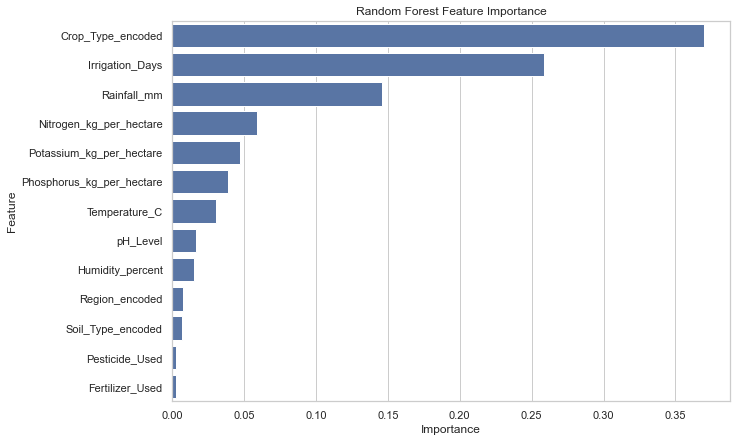

In [54]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=rf_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

In [55]:
print("Top 5 features according to Random Forest:")

rf_importance.head(5)

Top 5 features according to Random Forest:


,Feature,Importance
0,Crop_Type_encoded,0.369644
1,Irrigation_Days,0.258797
2,Rainfall_mm,0.145629
3,Nitrogen_kg_per_hectare,0.058958
4,Potassium_kg_per_hectare,0.047124


# Overfitting and Generalization Analysis

In [151]:
r2_gap = train_r2 - test_r2

print("Training R2:", round(train_r2, 4))
print("Testing R2 :", round(test_r2, 4))

print("\nR2 Gap:", round(r2_gap, 4))

if r2_gap <= 0.10:
    print("Interpretation: The train-test gap is relatively small.")
else:
    print("Interpretation: There is evidence of some overfitting.")

Training R2: 0.9902
Testing R2 : 0.8958

R2 Gap: 0.0944
Interpretation: The train-test gap is relatively small.


# MODEL COMPARISON

In [152]:
model_comparison = pd.DataFrame({
    'Model': [
        'Random Forest',
        'Gradient Boosting'
    ],
    'Test_R2': [
        rf_r2,
        test_r2
    ],
    'Test_RMSE': [
        rf_rmse,
        test_rmse
    ]
})

model_comparison.sort_values(
    by='Test_R2',
    ascending=False
).round(4)

,Model,Test_R2,Test_RMSE
1,Gradient Boosting,0.8958,0.4400
0,Random Forest,0.8149,0.5863


#  Actual vs Predicted Yield

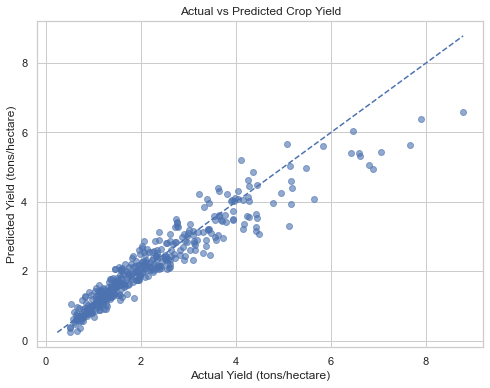

In [153]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.6
)

min_value = min(
    y_test.min(),
    y_test_pred.min()
)

max_value = max(
    y_test.max(),
    y_test_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Yield (tons/hectare)')
plt.ylabel('Predicted Yield (tons/hectare)')
plt.title('Actual vs Predicted Crop Yield')

plt.show()

# Prediction Error Analysis

In [154]:
residuals = y_test - y_test_pred

print("Mean Residual:", round(residuals.mean(), 4))
print("Residual Standard Deviation:", round(residuals.std(), 4))

Mean Residual: 0.0316
Residual Standard Deviation: 0.4394


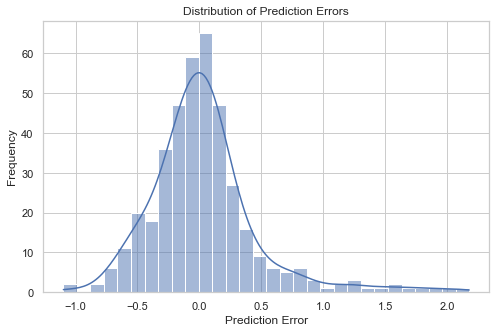

In [155]:
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.xlabel('Prediction Error')
plt.ylabel('Frequency')
plt.title('Distribution of Prediction Errors')

plt.show()

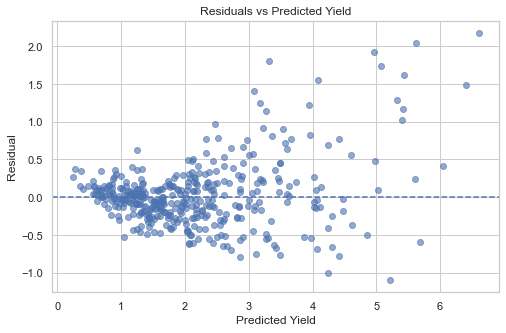

In [156]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel('Predicted Yield')
plt.ylabel('Residual')
plt.title('Residuals vs Predicted Yield')

plt.show()

# CLUSTER-WISE YIELD DISTRIBUTION

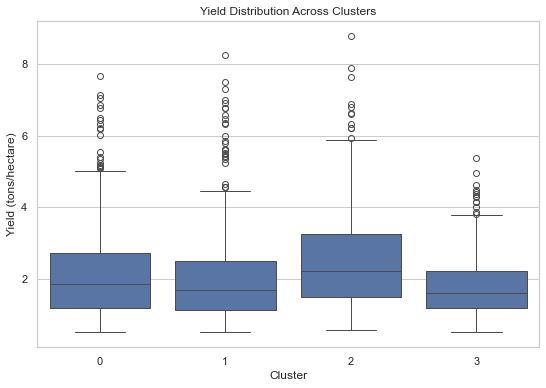

In [157]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='Cluster',
    y='Yield_tons_per_hectare'
)

plt.title('Yield Distribution Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Yield (tons/hectare)')

plt.show()

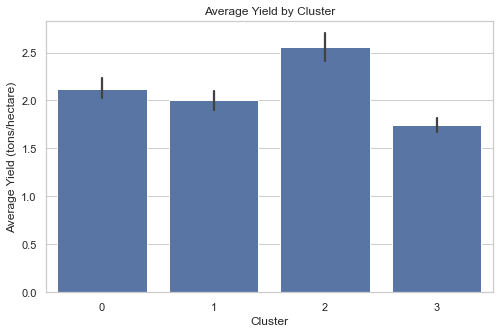

In [158]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Cluster',
    y='Yield_tons_per_hectare',
    estimator='mean'
)

plt.title('Average Yield by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Yield (tons/hectare)')

plt.show()

# Region-Soil Interaction by Cluster

In [159]:
region_soil_cluster = pd.crosstab(
    [
        df['Region'],
        df['Soil_Type']
    ],
    df['Cluster']
)

region_soil_cluster

Cluster             0   1   2   3
Region  Soil_Type                
Central Clay       34  27  12  27
        Loamy      24  25   5  28
        Sandy      23  25  19  29
        Silty      38  30  10  28
East    Clay       24  26  18  27
        Loamy      18  26  19  22
        Sandy      32  30  20  24
        Silty      34  39  20  21
North   Clay       28  21  20  39
        Loamy      28  34  18  24
        Sandy      20  36  18  20
        Silty      22  34  26  19
South   Clay       22  30  19  26
        Loamy      27  29  26  27
        Sandy      28  23  31  19
        Silty      20  36  27  22
West    Clay       34  28  20  15
        Loamy      28  35  16  18
        Sandy      25  24  23  19
        Silty      36  29  28  19

In [161]:
region_soil_yield = df.groupby(
    [
        'Region',
        'Soil_Type'
    ]
)['Yield_tons_per_hectare'].agg(
    ['count', 'mean', 'median']
).round(3)

region_soil_yield.sort_values(
    by='mean',
    ascending=False
)

count   mean  median
Region  Soil_Type                      
South   Loamy        109  2.607   2.330
East    Loamy         85  2.491   2.050
        Silty        114  2.307   1.855
South   Silty        105  2.304   1.960
West    Loamy         97  2.295   2.020
North   Loamy        104  2.288   1.970
Central Loamy         82  2.272   1.915
West    Silty        112  2.174   1.840
Central Silty        106  2.151   1.820
South   Clay          97  2.102   1.810
        Sandy        101  2.042   1.720
North   Silty        101  1.985   1.550
Central Sandy         96  1.973   1.890
East    Clay          95  1.963   1.790
        Sandy        106  1.952   1.720
North   Sandy         94  1.833   1.625
Central Clay         100  1.774   1.630
West    Sandy         91  1.749   1.500
North   Clay         108  1.700   1.445
West    Clay          97  1.677   1.550

# Statistical Test: Yield Differences Across Clusters

### Hypotheses

H0: The mean crop yield is the same across all clusters.

H1: At least one cluster has a different mean crop yield.

A one-way ANOVA is performed at α = 0.05.

In [76]:
cluster_groups = [
    group['Yield_tons_per_hectare'].values
    for _, group in df.groupby('Cluster')
]

f_stat, anova_p_value = f_oneway(
    *cluster_groups
)

print("ANOVA F-statistic:", round(f_stat, 4))
print("ANOVA p-value:", round(anova_p_value, 6))

if anova_p_value < 0.05:
    print(
        "\nConclusion: Reject H0."
        "\nThere is statistically significant evidence "
        "that mean yield differs across clusters."
    )
else:
    print(
        "\nConclusion: Fail to reject H0."
        "\nThere is insufficient evidence that mean yield "
        "differs across clusters."
    )

ANOVA F-statistic: 33.8594
ANOVA p-value: 0.0

Conclusion: Reject H0.
There is statistically significant evidence that mean yield differs across clusters.


# FINAL CLUSTER SUMMARY

In [165]:
final_cluster_summary = dominant_characteristics_df.copy()

final_cluster_summary = final_cluster_summary.sort_values(
    by='Mean_Yield',
    ascending=False
)

final_cluster_summary

,Cluster,Mean_Yield,Dominant_Crop,Dominant_Region,Dominant_Soil
2,2,2.558,Barley,South,Sandy
0,0,2.123,Corn,West,Silty
1,1,2.000,Wheat,North,Silty
3,3,1.746,Soybean,Central,Clay


# AUTOMATIC KEY FINDINGS

In [78]:
top_features = rf_importance.head(5)['Feature'].tolist()

print("Top 5 Random Forest Features:")
for i, feature in enumerate(top_features, start=1):
    print(f"{i}. {feature}")

print("\nTop-performing cluster:", top_cluster)
print(
    "Average yield of top cluster:",
    round(top_cluster_yield, 3),
    "tons/hectare"
)

print("\nFinal Gradient Boosting Test R²:",
      round(test_r2, 4))

print("Final Gradient Boosting Test RMSE:",
      round(test_rmse, 4))

print("Final Gradient Boosting Test MAE:",
      round(test_mae, 4))

print("\nANOVA p-value:",
      round(anova_p_value, 6))

Top 5 Random Forest Features:
1. Crop_Type_encoded
2. Irrigation_Days
3. Rainfall_mm
4. Nitrogen_kg_per_hectare
5. Potassium_kg_per_hectare

Top-performing cluster: 2
Average yield of top cluster: 2.558 tons/hectare

Final Gradient Boosting Test R²: 0.8958
Final Gradient Boosting Test RMSE: 0.44
Final Gradient Boosting Test MAE: 0.2945

ANOVA p-value: 0.0
